## Praktikum 1
##### Landmarkenerkennung für Gesichter

In diesem Praktikum betrachten wir die Grundlagen der Gesichtserkennung.

[Weitere Informationen zur Gesichtserkennung](https://melgor.github.io/blcv.github.io/static/2017/12/28/demystifying-face-recognition-iii-face-preprocessing/)

<div style="padding: 10px; border-left: 5px solid #B777FA; background-color: #5C18FA; border-radius: 4px">
  🐍 Bitte nutzen Sie die virtuelle Umgebung: <b>DLACV_2526</b>
</div>

In [2]:
# imports
import sys
import math
import dlib
import cv2
import matplotlib
import numpy as np
from utils import faceBlendCommon as fbc
from utils.renderFace import renderFace
from utils.dataPath import DATA_PATH
from utils.dataPath import MODEL_PATH
import matplotlib.pyplot as plt
%matplotlib inline

#### Teil 2: Gesichter ausrichten

Wir haben in Teil 1 das 68-Punkt-Modell aus der Vorlesung genutzt.

DLIB unterstützt aber auch ein kleineres Modell mit 5 Punkten - das reicht offensichtlich, um das Gesicht relativ zur Kamera auszurichten. Das Modell finden Sie auch im `data/models/`-Verzeichnis.

<center><img src="data/images/fld-5-point-model.jpg"></center>

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.1:</b><br>
  • Geben Sie an, was die einzelnen Merkmale des 5-Punkte-Modells angeben.
</div>

| Merkmalspunkt | Zeigt an |
|---------------|----------|
| 0 | Auge rechts außen |
| 1 | Auge rechts innen |
| 2 | Auge links außen |
| 3 | Auge links innen |
| 4 | Nasenspitze |

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.2:</b><br>
  • Schauen Sie sich in Ruhe die Datei <code>utils/faceBlendCommon.py</code> an. Sie ist als <code>fbc</code> in diesem Notebook importiert.<br>
  • Implementieren Sie die Funktion align_face, so dass die Funktion <code>fbc.normalizeImagesAndLandmarks</code> zum Einsatz kommt.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis 1:</b></i> Womöglich brauchen Sie mehr Funktionen aus <code>fbc</code> als <code>fbc.normalizeImagesAndLandmarks</code>.<br>
💡 <i><b>Hinweis 2:</b></i> Achten Sie darauf, in welchem Format die Methode <code>fbc.normalizeImagesAndLandmarks</code> das Eingabebild erwartet.
</div>

In [3]:
# Plt-Einstellungen
matplotlib.rcParams['figure.figsize'] = (6.0,6.0)
matplotlib.rcParams['image.cmap'] = 'gray'

# Konstante: 5-Punkt-Modell
PREDICTOR_PATH = MODEL_PATH + "shape_predictor_5_face_landmarks.dat"

# Gesichtsdetektor initialisieren
faceDetector = dlib.get_frontal_face_detector()
# Landmarkendetektor initialisieren
landmarkDetector = dlib.shape_predictor(PREDICTOR_PATH)

In [4]:
def align_face(im : np.ndarray, h : int = 600, w : int = 600) -> np.ndarray:
    """
    Align a face in an image.

    Parameters
    ----------
    im : np.ndarray
        Input image, shape (H, W, 3).
    h : int, optional
        Height of the output image, default is 600.
    w : int, optional
        Width of the output image, default is 600.

    Returns
    -------
    np.ndarray
        Aligned image of shape (h, w, 3).
    """
    dets = faceDetector(im)
    newRect = dlib.rectangle(int(dets[0].left()),
                          int(dets[0].top()),
                          int(dets[0].right()),
                          int(dets[0].bottom()))
    landmarks = landmarkDetector(im,newRect) 
    
    points = (fbc.dlibLandmarksToPoints(landmarks))
    img = fbc.normalizeImagesAndLandmarks((h,w), im, np.array(points))
    return img[0]

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 2.3:</b><br>
  • Lesen Sie die Bilder <code>data/images/face1.png</code> und <code>data/images/face2.png</code> ein.<br>
  • Wenden Sie die Funktion <code>align_face</code> auf die beiden Bilder an.<br>
  • Fügen Sie ein eigenes Bild von sich oder einer Person Ihrer Wahl in das Verzeichnis <code>data/images</code> ein. Wiederholen Sie die obigen Anweisungen für das neue Bild.<br>
  • Geben Sie sowohl die Originalbilder als auch die Gesichter im Jupyter-Notebook aus. Wählen Sie dabei passende Namen für die einzelnen Spalten.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Achten Sie darauf, dass möglichst nur ein Gesicht auf Ihrem Bild zu sehen ist, das Gesicht möglichst gerade in die Kamera schaut und nicht zu sehr verdeckt ist. Das Modell muss schließlich die 5 Punkte erkennen.
</div>

[[ 2.09371243e+00  3.37035488e-01 -4.34542152e+02]
 [-3.37035488e-01  2.09371243e+00 -2.33333560e+02]]
[[ 2.14129960e+00 -3.42578424e-01 -2.43992240e+01]
 [ 3.42578424e-01  2.14129960e+00 -4.12827467e+02]]
[[ 2.43842202e+00 -6.07706422e-01 -4.75476440e+02]
 [ 6.07706422e-01  2.43842202e+00 -1.25015464e+03]]


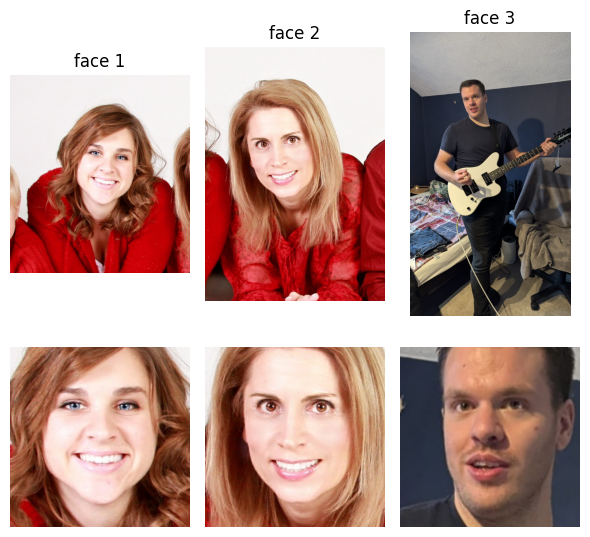

In [5]:
# Einlesen
img_1 = cv2.imread("data/images/face1.png")
img_1 = cv2.cvtColor(img_1, cv2.COLOR_RGB2BGR)
img_1_on = align_face(img_1)
img_2 = cv2.imread("data/images/face2.png")
img_2 = cv2.cvtColor(img_2, cv2.COLOR_RGB2BGR)
img_2_on = align_face(img_2)
img_3 = cv2.imread("data/images/personal_person.jpeg")
img_3 = cv2.cvtColor(img_3, cv2.COLOR_RGB2BGR)
img_3_on = align_face(img_3)

# Anzeigen
fig, axes = plt.subplots(2, 3)


axes[0, 0].imshow(img_1)
axes[0, 0].axis('off')
axes[0, 0].set_title("face 1")

axes[1, 0].imshow(img_1_on)
axes[1, 0].axis('off')

axes[0, 1].imshow(img_2)
axes[0, 1].axis('off')
axes[0, 1].set_title("face 2")

axes[1, 1].imshow(img_2_on)
axes[1, 1].axis('off')

axes[0, 2].imshow(img_3)
axes[0, 2].axis('off')
axes[0, 2].set_title("face 3")

axes[1, 2].imshow(img_3_on)
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()